In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp

from src import IS_CUPY_BACKEND, xp
from src.logging_utils import setup_logging
from src.surrogate import HATANNSurrogate

setup_logging()

DIM = 3
TOL = 0.01
N_TRAIN = 3000


SIGMA, RHO, BETA = 10.0, 28.0, 8 / 3
TF_STEP = 0.01
TOTAL_TIME = 10
cwd = Path.cwd()
model_path = (
    cwd
    / "models"
    / f"lorenz63_ntrain{N_TRAIN}_tol{TOL}_tf{TF_STEP}_total_time{TOTAL_TIME}.npz"
)


def lorenz63_vector_field(x):
    return np.array(
        [SIGMA * (x[1] - x[0]), x[0] * (RHO - x[2]) - x[1], x[0] * x[1] - BETA * x[2]]
    )


def lorenz63_jacobian(x):
    return np.array([[-SIGMA, SIGMA, 0], [RHO - x[2], -1, -x[0]], [x[1], x[0], -BETA]])


def flowmap_with_sensitivity(x0, tf=0.01):
    d = len(x0)
    initial_condition = np.hstack([x0, np.eye(d).flatten()])

    def sensitivity_ode(t, y):
        x = y[:d]
        J = y[d:].reshape((d, d))
        dxdt = lorenz63_vector_field(x)
        dJdt = lorenz63_jacobian(x) @ J
        return np.hstack([dxdt, dJdt.flatten()])

    # Tightened tolerances for smoother results
    sol = solve_ivp(
        sensitivity_ode,
        [0, tf],
        initial_condition,
        method="RK45",
        rtol=1e-10,
        atol=1e-12,
    )
    yf = sol.y[:, -1]
    return yf[:d], yf[d:].reshape((d, d))


def batch_flowmap_grad(X0, tf=0.01):
    N, d = X0.shape
    XF, GF = np.zeros((N, d)), np.zeros((N, d, d))
    for i in range(N):
        XF[i], GF[i] = flowmap_with_sensitivity(X0[i], tf)
    return XF, GF


X_train_cpu = np.random.uniform(-15, 15, size=(N_TRAIN, DIM))
X_train = xp.asarray(X_train_cpu) if IS_CUPY_BACKEND else X_train_cpu
surrogate = HATANNSurrogate(version="v2")


def lorenz_oracle(x):
    xf, gf = batch_flowmap_grad(x, tf=TF_STEP)
    return xp.asarray(xf), xp.asarray(gf)


print("Training Surrogate...")
surrogate.train(
    X_train=X_train,
    oracle_fn=lorenz_oracle,
    TOL=TOL,
    NUM_INITIAL_CLUSTERS=100,
    USE_HESSIAN_INFORMED_SPLIT=True,
    ERROR_METRIC="Linf-local",
    save_model=model_path,
    load_if_exists=True,
)

2026-02-02 13:51:16 - root - INFO - Logging to file: /home/prajwal/github-repos/knnsur/.logs/20260202_135116.log
Training Surrogate...
2026-02-02 13:51:16 - src.surrogate - INFO - Model loaded from /home/prajwal/github-repos/knnsur/models/lorenz63_ntrain3000_tol0.1_tf0.01_total_time10.npz
2026-02-02 13:51:16 - src.surrogate - INFO - Loaded model with 100 clusters
2026-02-02 13:51:16 - src.surrogate - INFO - Loaded existing model from /home/prajwal/github-repos/knnsur/models/lorenz63_ntrain3000_tol0.1_tf0.01_total_time10.npz


In [15]:
%matplotlib widget

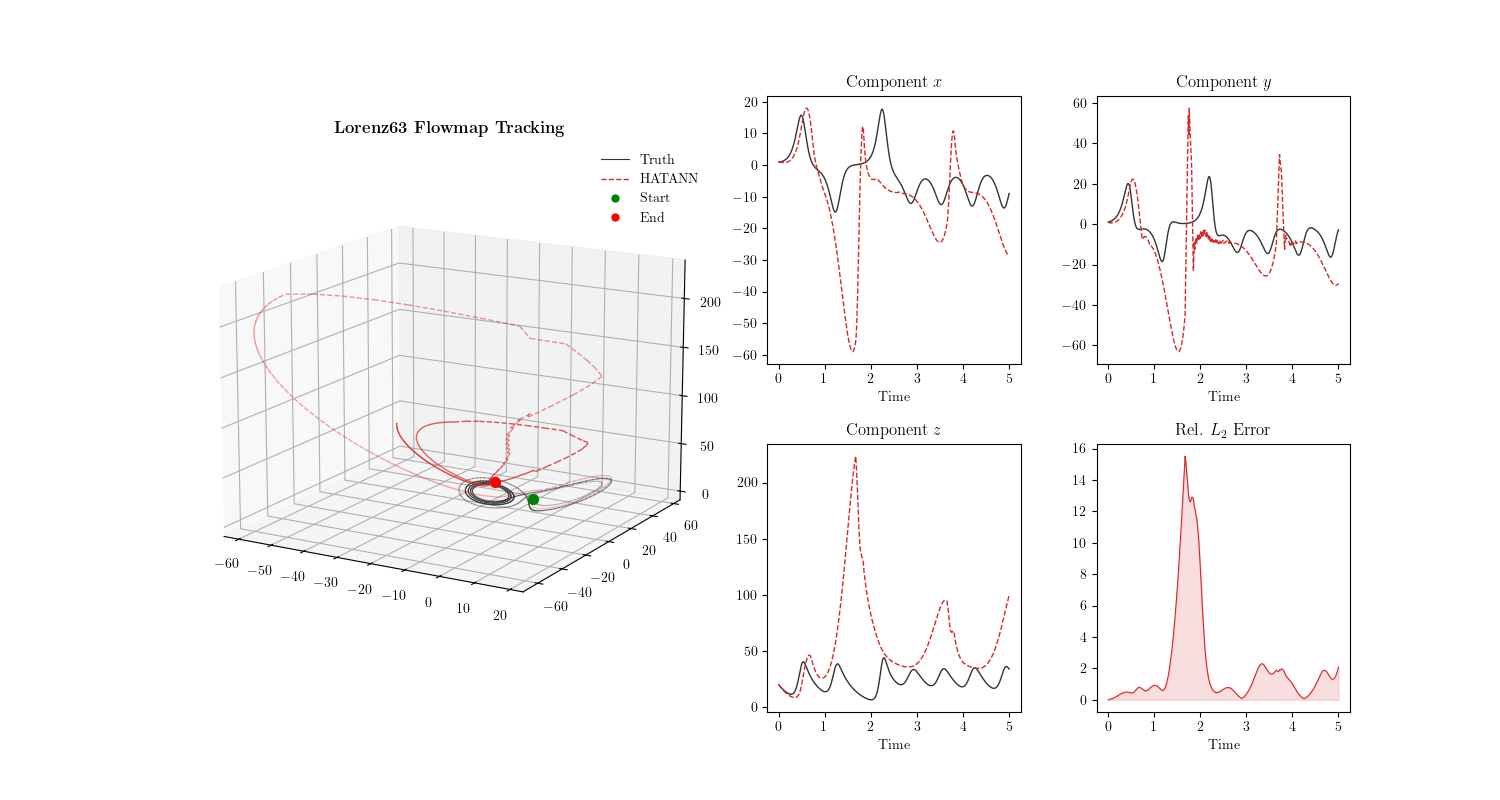

In [ ]:
PREDICT_TIME = 10
assert PREDICT_TIME <= TOTAL_TIME, f"PREDICT_TIME must be less than {TOTAL_TIME}"
# Recursive Simulation with finer steps
STEPS = int(PREDICT_TIME / TF_STEP)
t_axis = np.linspace(0, PREDICT_TIME, STEPS + 1)
x0 = np.array([[1.0, 1.0, 20.0]])

true_path, surr_path = [x0[0]], [x0[0]]
curr_true, curr_surr = x0, xp.asarray(x0) if IS_CUPY_BACKEND else x0

for _ in range(STEPS):
    curr_true, _ = batch_flowmap_grad(curr_true, tf=TF_STEP)
    true_path.append(curr_true[0])
    pred, _ = surrogate.predict(curr_surr, k_nn=1)
    curr_surr = pred
    surr_path.append(pred[0])


true = np.array(true_path).T
surr = np.array(surr_path).T
time = t_axis

# Plotting
plt.rcParams.update(
    {"text.usetex": True, "font.family": "serif", "figure.figsize": (15, 8)}
)
fig = plt.figure()
gs = GridSpec(1, 2, width_ratios=[0.9, 1], wspace=0.1)

# Smooth 3D Butterfly
ax3d = fig.add_subplot(gs[0], projection="3d")

# Plot true path with varying alpha
n_points = true.shape[1]
alphas = np.linspace(0.2, 1.0, n_points)
for i in range(n_points - 1):
    ax3d.plot(
        true[0, i : i + 2],
        true[1, i : i + 2],
        true[2, i : i + 2],
        color="#333333",
        lw=0.8,
        alpha=alphas[i],
    )

# Plot surrogate path with varying alpha
for i in range(n_points - 1):
    ax3d.plot(
        surr[0, i : i + 2],
        surr[1, i : i + 2],
        surr[2, i : i + 2],
        color="#d62728",
        ls="--",
        lw=1.0,
        alpha=alphas[i],
    )

ax3d.scatter(true[0, 0], true[1, 0], true[2, 0], color="green", s=50, label="Start")
ax3d.scatter(true[0, -1], true[1, -1], true[2, -1], color="red", s=50, label="End")
ax3d.view_init(elev=15, azim=-60)
ax3d.set_title(r"\textbf{Lorenz63 Flowmap Tracking}")

legend_elements = [
    Line2D([0], [0], color="#333333", lw=0.8, label="Truth"),
    Line2D([0], [0], color="#d62728", ls="--", lw=1.0, label="HATANN"),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="green",
        markersize=7,
        label="Start",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="red",
        markersize=7,
        label="End",
    ),
]
ax3d.legend(handles=legend_elements, frameon=False)

# Components and Error
gs_sub = gs[1].subgridspec(2, 2, hspace=0.3, wspace=0.3)
labels = ["x", "y", "z"]
for i in range(3):
    ax = fig.add_subplot(gs_sub[i // 2, i % 2])
    ax.plot(time, true[i], color="#333333", lw=1)
    ax.plot(time, surr[i], color="#d62728", ls="--", lw=1)
    ax.set_title(f"Component ${labels[i]}$")
    ax.set_xlabel("Time")

ax_err = fig.add_subplot(gs_sub[1, 1])
err = np.linalg.norm(true - surr, axis=0) / (np.linalg.norm(true, axis=0) + 1e-10)
ax_err.fill_between(time, err, color="#d62728", alpha=0.15)
ax_err.plot(time, err, color="#d62728", lw=0.8)
ax_err.set_title(r"Rel. $L_2$ Error")
ax_err.set_xlabel("Time")

plt.show()